# PV Project

## Data Exploration

### Import Libraries & Load the data

In [ ]:
%pip install matplotlib seaborn

In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
# Establishing connection wit the database

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DB_PATH = PROJECT_ROOT / "data" / "faers_db.duckdb"

con = duckdb.connect(str(DB_PATH), read_only=True) # read_only=True for exploration, and read_only=False only when creating tables.

In [3]:
pd.set_option("display.max_columns", 50, "display.width", 200)

In [4]:
print(con.sql("SHOW TABLES").df())

                 name
0          clean_demo
1    glp1_case_events
2         glp1_cohort
3   glp1_unique_cases
4            raw_drug
5            raw_reac
6   sglt2_case_events
7        sglt2_cohort
8  sglt2_unique_cases


In [6]:
for t in con.sql("SHOW TABLES").df()["name"]:
    n = con.sql(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
    print(f"{t}: {n:,} rows")
    print(con.sql(f"DESCRIBE {t}").df()[["column_name", "column_type"]], "\n")

clean_demo: 7,443,175 rows
         column_name column_type
0          primaryid     VARCHAR
1             caseid     VARCHAR
2        caseversion     VARCHAR
3           i_f_code     VARCHAR
4           event_dt     VARCHAR
5             mfr_dt     VARCHAR
6        init_fda_dt     VARCHAR
7             fda_dt     VARCHAR
8           rept_cod     VARCHAR
9           auth_num     VARCHAR
10           mfr_num     VARCHAR
11          mfr_sndr     VARCHAR
12           lit_ref     VARCHAR
13               age     VARCHAR
14           age_cod     VARCHAR
15           age_grp     VARCHAR
16               sex     VARCHAR
17             e_sub     VARCHAR
18                wt     VARCHAR
19            wt_cod     VARCHAR
20           rept_dt     VARCHAR
21            to_mfr     VARCHAR
22          occp_cod     VARCHAR
23  reporter_country     VARCHAR
24      occr_country     VARCHAR
25          gndr_cod     VARCHAR 

glp1_case_events: 96,217 rows
        column_name column_type
0            casei

In [7]:
# 1. Cases your filter would have missed, found via prod_ai
print(con.sql("""
SELECT COUNT(DISTINCT primaryid) AS missed_ps_cases FROM read_csv(
    {drug_files}, delim='$', header=True, all_varchar=True, union_by_name=True,
    ignore_errors=True, quote='')
WHERE upper(role_cod)='PS'
  AND regexp_matches(lower(coalesce(prod_ai,'')), 'gliflozin')
  AND NOT regexp_matches(upper(drugname),
      'JARDIANCE|EMPAGLIFLOZIN|FARXIGA|DAPAGLIFLOZIN|INVOKANA|CANAGLIFLOZIN|STEGLATRO|ERTUGLIFLOZIN')
""".format(drug_files=drug_files)).df())

# 2. Row inflation: rows vs distinct case-event pairs
print(con.sql("""
SELECT COUNT(*) AS rows, COUNT(DISTINCT (caseid, adverse_event)) AS distinct_pairs,
       COUNT(DISTINCT caseid) AS cases FROM sglt2_cohort""").df())

NameError: name 'drug_files' is not defined

In [ ]:


def q(sql, read_only=True):
    con = duckdb.connect(str(DB_PATH), read_only=read_only)
    try:
        return con.sql(sql).df()
    finally:
        con.close()

## Initial Data Exploration

In [10]:
checks = {
 "cases_in_drug": "SELECT COUNT(DISTINCT primaryid) n FROM raw_drug",
 "cases_in_reac": "SELECT COUNT(DISTINCT primaryid) n FROM raw_reac",
 "cases_in_demo": "SELECT COUNT(DISTINCT primaryid) n FROM clean_demo",
 "dup_cases_in_demo": "SELECT COUNT(*) - COUNT(DISTINCT caseid) n FROM clean_demo",
}
for name, sql in checks.items():
    print(name, q(sql).iloc[0, 0])

print(q("""
SELECT substr(c.fda_dt,1,4) AS yr, COUNT(DISTINCT d.primaryid) AS drug_cases
FROM raw_drug d
JOIN clean_demo c ON CAST(c.primaryid AS BIGINT) = d.primaryid
GROUP BY 1 ORDER BY 1
"""))

print(q("SELECT role_cod, COUNT(*) n FROM sglt2_cohort GROUP BY 1 ORDER BY 2 DESC"))
print(q("""SELECT drugname, COUNT(DISTINCT primaryid) n
          FROM sglt2_cohort GROUP BY 1 ORDER BY 2 DESC LIMIT 40"""))

cases_in_drug 260020
cases_in_reac 8309565
cases_in_demo 7443175
dup_cases_in_demo 0
     yr  drug_cases
0  2013        1906
1  2014      234321
  role_cod      n
0       PS  84756
                                             drugname      n
0                                            INVOKANA  19657
1                                           JARDIANCE  10006
2                                             FARXIGA   4456
3                                       CANAGLIFLOZIN    745
4                                       DAPAGLIFLOZIN    519
5                                      DAPAGLIFLOZIN.    507
6                                       EMPAGLIFLOZIN    486
7                                           STEGLATRO    354
8                                       JARDIANCE DUO     78
9                               BLINDED DAPAGLIFLOZIN     24
10                              BLINDED ERTUGLIFLOZIN     11
11                      DAPAGLIFLOZIN CODE NOT BROKEN     10
12                        

In [11]:
print(q("SELECT substr(fda_dt,1,4) yr, COUNT(*) n FROM clean_demo GROUP BY 1 ORDER BY 1"))


     yr        n
0  2013     3885
1  2014   813086
2  2015  1227634
3  2016  1154256
4  2017  1217770
5  2018  1448432
6  2019  1578112


In [6]:
for t in ["clean_demo","raw_drug","raw_reac","sglt2_cohort","sglt2_case_events","sglt2_unique_cases"]:
    print("\n==", t)
    display(con.sql(f"DESCRIBE {t}").df())
    display(con.sql(f"SELECT * FROM {t} LIMIT 5").df())
    print(con.sql(f"SELECT COUNT(*) FROM {t}").fetchone()[0])


== clean_demo


,column_name,column_type,null,key,default,extra
0,primaryid,VARCHAR,YES,None,None,None
1,caseid,VARCHAR,YES,None,None,None
2,caseversion,VARCHAR,YES,None,None,None
3,i_f_code,VARCHAR,YES,None,None,None
4,event_dt,VARCHAR,YES,None,None,None
5,mfr_dt,VARCHAR,YES,None,None,None
6,init_fda_dt,VARCHAR,YES,None,None,None
7,fda_dt,VARCHAR,YES,None,None,None
8,rept_cod,VARCHAR,YES,None,None,None
9,auth_num,VARCHAR,YES,None,None,None


,primaryid,caseid,caseversion,i_f_code,event_dt,mfr_dt,init_fda_dt,fda_dt,rept_cod,auth_num,...,sex,e_sub,wt,wt_cod,rept_dt,to_mfr,occp_cod,reporter_country,occr_country,gndr_cod
0,109658262,10965826,2,F,201407,20150402,20150330,20150403,EXP,None,...,M,Y,99.43,KG,20150403,N,MD,US,US,None
1,109658461,10965846,1,I,None,20150319,20150330,20150330,EXP,None,...,F,Y,None,None,20150326,N,CN,US,US,None
2,109659221,10965922,1,I,None,20150224,20150330,20150330,PER,None,...,F,Y,None,None,20150330,N,CN,US,US,None
3,109660191,10966019,1,I,20140830,20140902,20150330,20150330,PER,None,...,F,Y,None,None,20150330,N,CN,US,US,None
4,109661211,10966121,1,I,20101108,20101108,20150330,20150330,PER,None,...,F,Y,55,KG,20150330,N,MD,JP,JP,None


7443175

== raw_drug


,column_name,column_type,null,key,default,extra
0,primaryid,BIGINT,YES,None,None,None
1,caseid,BIGINT,YES,None,None,None
2,drug_seq,BIGINT,YES,None,None,None
3,role_cod,VARCHAR,YES,None,None,None
4,drugname,VARCHAR,YES,None,None,None
5,val_vbm,BIGINT,YES,None,None,None
6,route,VARCHAR,YES,None,None,None
7,dose_vbm,VARCHAR,YES,None,None,None
8,cum_dose_chr,DOUBLE,YES,None,None,None
9,cum_dose_unit,VARCHAR,YES,None,None,None


,primaryid,caseid,drug_seq,role_cod,drugname,val_vbm,route,dose_vbm,cum_dose_chr,cum_dose_unit,dechal,rechal,lot_num,exp_dt,nda_num,dose_amt,dose_unit,dose_form,dose_freq
0,100033001,10003300,1,PS,BONIVA,1,INTRAVENOUS,"3 MG, 1 IN 3 M, INTRAVENOUS (NOT OTHERWISE SPE...",NaN,None,D,D,H6200HO3,<NA>,021858,3,MG,None,None
1,100033011,10003301,1,PS,IBUPROFEN,1,None,None,NaN,None,U,U,None,<NA>,17463,None,None,None,None
2,100033021,10003302,1,PS,Lyrica,1,None,UNK,NaN,None,None,D,None,<NA>,021446,None,None,None,None
3,100033051,10003305,1,PS,Lipitor,1,None,UNK,NaN,None,None,D,None,<NA>,020702,None,None,FILM-COATED TABLET,None
4,100033051,10003305,2,SS,LISINOPRIL,1,None,UNK,NaN,None,None,D,None,<NA>,None,None,None,None,None


... (9 outputs left out)

84756

== sglt2_unique_cases


,column_name,column_type,null,key,default,extra
0,caseid,VARCHAR,YES,None,None,None
1,primaryid,VARCHAR,YES,None,None,None
2,age,DOUBLE,YES,None,None,None
3,age_cod,VARCHAR,YES,None,None,None
4,sex,VARCHAR,YES,None,None,None
5,reporter_country,VARCHAR,YES,None,None,None
6,fda_dt,VARCHAR,YES,None,None,None
7,drugname,VARCHAR,YES,None,None,None


,caseid,primaryid,age,age_cod,sex,reporter_country,fda_dt,drugname
0,13714604,137146041,NaN,None,F,US,20170704,INVOKANA
1,13714618,137146181,NaN,None,F,US,20170704,INVOKANA
2,13714656,137146561,70.0,YR,M,US,20170704,INVOKANA
3,13714658,137146581,NaN,None,None,US,20170704,INVOKANA
4,13714673,137146731,NaN,None,None,US,20170704,INVOKANA


36983


In [7]:
checks = {
 "cases_in_drug": "SELECT COUNT(DISTINCT primaryid) n FROM raw_drug",
 "cases_in_reac": "SELECT COUNT(DISTINCT primaryid) n FROM raw_reac",
 "cases_in_demo": "SELECT COUNT(DISTINCT primaryid) n FROM clean_demo",
 "dup_cases_in_demo": "SELECT COUNT(*) - COUNT(DISTINCT caseid) n FROM clean_demo",
}
for name, sql in checks.items():
    print(name, q(sql).iloc[0, 0])

print(q("""
SELECT substr(c.fda_dt,1,4) AS yr, COUNT(DISTINCT d.primaryid) AS drug_cases
FROM raw_drug d
JOIN clean_demo c ON CAST(c.primaryid AS BIGINT) = d.primaryid
GROUP BY 1 ORDER BY 1
"""))

print(q("SELECT role_cod, COUNT(*) n FROM sglt2_cohort GROUP BY 1 ORDER BY 2 DESC"))
print(q("""SELECT drugname, COUNT(DISTINCT primaryid) n
          FROM sglt2_cohort GROUP BY 1 ORDER BY 2 DESC LIMIT 40"""))

NameError: name 'q' is not defined

1. DEMOGRAPHIC SUMMARY COMPARISON


,cohort,total_cases,mean_age,median_age,pct_female,pct_male
0,SGLT2,36983,601.6,58.0,43.5,43.7
1,GLP1,41266,59.5,60.0,57.0,37.5



2. TEMPORAL REPORTING TRENDS (2014-2019)


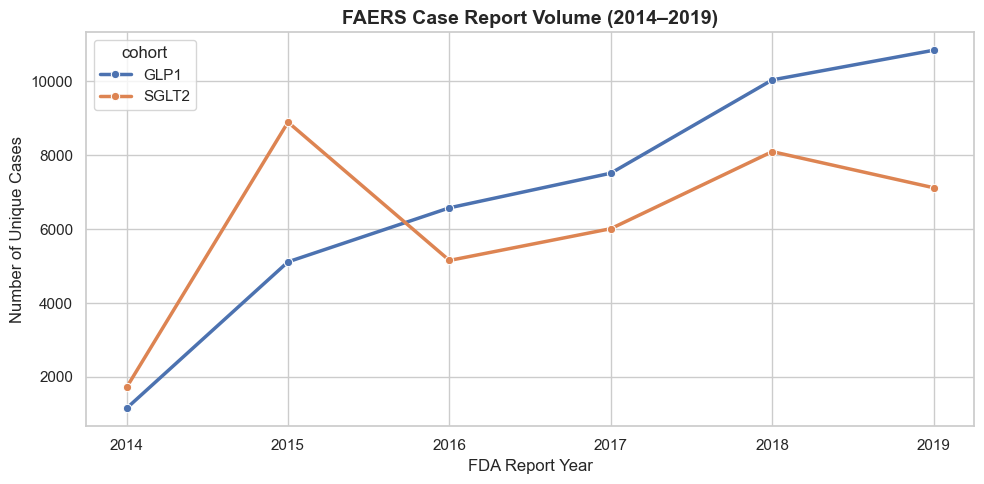


3. DISPROPORTIONALITY SIGNALS (SGLT2 vs GLP-1)


,adverse_event,sglt2_cases,glp1_cases,PRR,ROR,95% CI
0,DIABETIC KETOACIDOSIS,5294,192,30.77,35.74,[30.92 - 41.30]
1,FUNGAL INFECTION,2639,81,36.35,39.07,[31.31 - 48.76]
2,TOE AMPUTATION,2024,1,2258.40,2389.09,[336.34 - 16970.06]
3,ACUTE KIDNEY INJURY,1972,213,10.33,10.86,[9.42 - 12.51]
4,OSTEOMYELITIS,1932,9,239.53,252.67,[131.25 - 486.44]
5,WEIGHT DECREASED,1836,1713,1.20,1.21,[1.13 - 1.29]
6,URINARY TRACT INFECTION,1485,173,9.58,9.94,[8.48 - 11.64]
7,BLOOD GLUCOSE INCREASED,1364,4070,0.37,0.35,[0.33 - 0.37]
8,KETOACIDOSIS,1264,30,47.01,48.64,[33.86 - 69.88]
9,DIZZINESS,1233,1054,1.31,1.32,[1.21 - 1.43]


In [3]:


sns.set_theme(style="whitegrid")

with duckdb.connect(str(DB_PATH), read_only=True) as con:
    
    print("==================================================")
    print("1. DEMOGRAPHIC SUMMARY COMPARISON")
    print("==================================================")

    demo_query = """
    SELECT 
        'SGLT2' AS cohort,
        COUNT(*) AS total_cases,
        ROUND(AVG(age), 1) AS mean_age,
        ROUND(MEDIAN(age), 1) AS median_age,
        ROUND(COUNT(CASE WHEN UPPER(sex) = 'F' THEN 1 END) * 100.0 / COUNT(*), 1) AS pct_female,
        ROUND(COUNT(CASE WHEN UPPER(sex) = 'M' THEN 1 END) * 100.0 / COUNT(*), 1) AS pct_male
    FROM sglt2_unique_cases

    UNION ALL

    SELECT 
        'GLP1' AS cohort,
        COUNT(*) AS total_cases,
        ROUND(AVG(age), 1) AS mean_age,
        ROUND(MEDIAN(age), 1) AS median_age,
        ROUND(COUNT(CASE WHEN UPPER(sex) = 'F' THEN 1 END) * 100.0 / COUNT(*), 1) AS pct_female,
        ROUND(COUNT(CASE WHEN UPPER(sex) = 'M' THEN 1 END) * 100.0 / COUNT(*), 1) AS pct_male
    FROM glp1_unique_cases;
    """
    df_demo = con.execute(demo_query).df()
    display(df_demo)

    print("\n==================================================")
    print("2. TEMPORAL REPORTING TRENDS (2014-2019)")
    print("==================================================")

    trend_query = """
    SELECT 
        TRY_CAST(SUBSTRING(fda_dt, 1, 4) AS INT) AS report_year,
        'SGLT2' AS cohort,
        COUNT(*) AS case_count
    FROM sglt2_unique_cases
    WHERE TRY_CAST(SUBSTRING(fda_dt, 1, 4) AS INT) BETWEEN 2014 AND 2019
    GROUP BY report_year

    UNION ALL

    SELECT 
        TRY_CAST(SUBSTRING(fda_dt, 1, 4) AS INT) AS report_year,
        'GLP1' AS cohort,
        COUNT(*) AS case_count
    FROM glp1_unique_cases
    WHERE TRY_CAST(SUBSTRING(fda_dt, 1, 4) AS INT) BETWEEN 2014 AND 2019
    GROUP BY report_year
    ORDER BY report_year, cohort;
    """
    df_trends = con.execute(trend_query).df()

    plt.figure(figsize=(10, 5))
    sns.lineplot(data=df_trends, x="report_year", y="case_count", hue="cohort", marker="o", linewidth=2.5)
    plt.title("FAERS Case Report Volume (2014–2019)", fontsize=14, fontweight="bold")
    plt.xlabel("FDA Report Year", fontsize=12)
    plt.ylabel("Number of Unique Cases", fontsize=12)
    plt.xticks(range(2014, 2020))
    plt.tight_layout()
    plt.show()

    print("\n==================================================")
    print("3. DISPROPORTIONALITY SIGNALS (SGLT2 vs GLP-1)")
    print("==================================================")

    signal_query = """
    WITH sglt2_counts AS (
        SELECT 
            adverse_event,
            COUNT(DISTINCT caseid) AS a
        FROM sglt2_case_events
        WHERE adverse_event IS NOT NULL
        GROUP BY adverse_event
    ),
    glp1_counts AS (
        SELECT 
            adverse_event,
            COUNT(DISTINCT caseid) AS c
        FROM glp1_case_events
        WHERE adverse_event IS NOT NULL
        GROUP BY adverse_event
    ),
    totals AS (
        SELECT 
            (SELECT COUNT(DISTINCT caseid) FROM sglt2_unique_cases) AS total_sglt2_cases,
            (SELECT COUNT(DISTINCT caseid) FROM glp1_unique_cases) AS total_glp1_cases
    )
    SELECT 
        s.adverse_event,
        s.a AS a,                                                  -- Cell a
        t.total_sglt2_cases - s.a AS b,                            -- Cell b
        COALESCE(g.c, 0) AS c,                                     -- Cell c
        t.total_glp1_cases - COALESCE(g.c, 0) AS d,                -- Cell d
        t.total_sglt2_cases,
        t.total_glp1_cases
    FROM sglt2_counts s
    LEFT JOIN glp1_counts g ON s.adverse_event = g.adverse_event
    CROSS JOIN totals t
    WHERE s.a >= 10 AND COALESCE(g.c, 0) >= 1                      -- Ensure valid non-zero counts for logs
    ORDER BY s.a DESC
    LIMIT 30;
    """
    df_signals = con.execute(signal_query).df()

# Calculate PRR, ROR, and 95% Confidence Intervals
df_signals["PRR"] = (df_signals["a"] / df_signals["total_sglt2_cases"]) / (df_signals["c"] / df_signals["total_glp1_cases"])
df_signals["ROR"] = (df_signals["a"] * df_signals["d"]) / (df_signals["b"] * df_signals["c"])

df_signals["se_ln_ror"] = np.sqrt((1/df_signals["a"]) + (1/df_signals["b"]) + (1/df_signals["c"]) + (1/df_signals["d"]))
df_signals["ROR_CI_lower"] = np.exp(np.log(df_signals["ROR"]) - 1.96 * df_signals["se_ln_ror"])
df_signals["ROR_CI_upper"] = np.exp(np.log(df_signals["ROR"]) + 1.96 * df_signals["se_ln_ror"])

# Display formatted table
df_display = df_signals.copy()
df_display["PRR"] = df_display["PRR"].round(2)
df_display["ROR"] = df_display["ROR"].round(2)
df_display["95% CI"] = df_display.apply(lambda r: f"[{r['ROR_CI_lower']:.2f} - {r['ROR_CI_upper']:.2f}]", axis=1)

# Rename columns for presentation
df_display = df_display.rename(columns={"a": "sglt2_cases", "c": "glp1_cases"})
display(df_display[["adverse_event", "sglt2_cases", "glp1_cases", "PRR", "ROR", "95% CI"]].head(20))